# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [5]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [6]:
# PLIK_LODZ = "przecitne-miesiczne-wynagrodzenia-brutto-ogolem.csv"
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [7]:
# Preview first 5 lines of raw CSV
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())


﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [8]:
# TODO: wczytaj plik do ramki `df` z właściwym separatorem
df = pd.read_csv(PLIK_LODZ, sep=";")

# TODO: wyświetl pierwsze wiersze, wymiary i typy kolumn
print("First 5 rows:")
print(df.head())
print(f"\nShape: {df.shape}")
print("\nDataFrame info:")
df.info()


First 5 rows:
                 name   rok  wartość   zmienna
0  Szkolnictwo wyższe  2012       22  uczelnie
1  Szkolnictwo wyższe  2013       22  uczelnie
2  Szkolnictwo wyższe  2014       23  uczelnie
3  Szkolnictwo wyższe  2015       21  uczelnie
4  Szkolnictwo wyższe  2016       20  uczelnie

Shape: (65, 4)

DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   name     65 non-null     str  
 1   rok      65 non-null     int64
 2   wartość  65 non-null     int64
 3   zmienna  65 non-null     str  
dtypes: int64(2), str(2)
memory usage: 2.2 KB


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:*
- Separator - średnik (;)
- Typ kolumny `wartość` - została poprawnie sparsowana jako liczba całkowita (`int64`).
- Polskie znaki: - nazwy kolumn zawierające polskie znaki diakrytyczne (np. `wartość`) wczytały się poprawnie dzięki kodowaniu UTF-8.


## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [9]:
# TODO: jakie są zmienne i ile mają wierszy?
print("Variable value counts:")
print(df["zmienna"].value_counts())

# TODO: format szeroki (pivot) — wynik zapisz w `szeroka`
szeroka = df.pivot(index="rok", columns="zmienna", values="wartość")
szeroka


Variable value counts:
zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [10]:
# TODO: policz różnicę (kobiety + mężczyźni) − ogółem dla każdego roku
diff = (szeroka["kobiety"] + szeroka["mężczyźni"]) - szeroka["ogółem"]
print("Difference per year (kobiety + mężczyźni - ogółem):")
print(diff)

is_consistent = (diff == 0).all()
print(f"\nData consistent across all years: {is_consistent}")


Difference per year (kobiety + mężczyźni - ogółem):
rok
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
dtype: int64

Data consistent across all years: True


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [11]:
# TODO: statystyki opisowe
metric_cols = ["absolwenci ogółem", "kobiety", "mężczyźni", "ogółem", "uczelnie"]
print("Summary statistics (2012-2024):")
print(szeroka[metric_cols].describe())

# TODO: zmiana procentowa 2012 → 2024
pct_change_2012_2024 = ((szeroka.loc[2024, metric_cols] - szeroka.loc[2012, metric_cols]) / szeroka.loc[2012, metric_cols]) * 100
print("\nPercentage change 2012 -> 2024 [%]:")
print(pct_change_2012_2024.round(1))

# TODO: nowe kolumny
szeroka["udzial_kobiet"] = szeroka["kobiety"] / szeroka["ogółem"]
szeroka["studenci_na_uczelnie"] = szeroka["ogółem"] / szeroka["uczelnie"]

print("\nDataFrame with derived indicators:")
print(szeroka)


Summary statistics (2012-2024):
zmienna  absolwenci ogółem  kobiety  mężczyźni   ogółem  uczelnie
count                13.00    13.00      13.00    13.00     13.00
mean              17780.54 43010.92   28793.92 71804.85     19.54
std                3522.40  5391.05    3524.63  8900.65      2.44
min               14082.00 38146.00   25710.00 64272.00     15.00
25%               14756.00 39170.00   26049.00 65297.00     18.00
50%               17046.00 39958.00   26297.00 66002.00     20.00
75%               19835.00 45584.00   30769.00 76353.00     22.00
max               24825.00 55265.00   36281.00 91546.00     23.00

Percentage change 2012 -> 2024 [%]:
zmienna
absolwenci ogółem   -41.30
kobiety             -30.20
mężczyźni           -29.10
ogółem              -29.80
uczelnie            -31.80
dtype: float64

DataFrame with derived indicators:
zmienna  absolwenci ogółem  kobiety  mężczyźni  ogółem  uczelnie  \
rok                                                                
2012   

## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

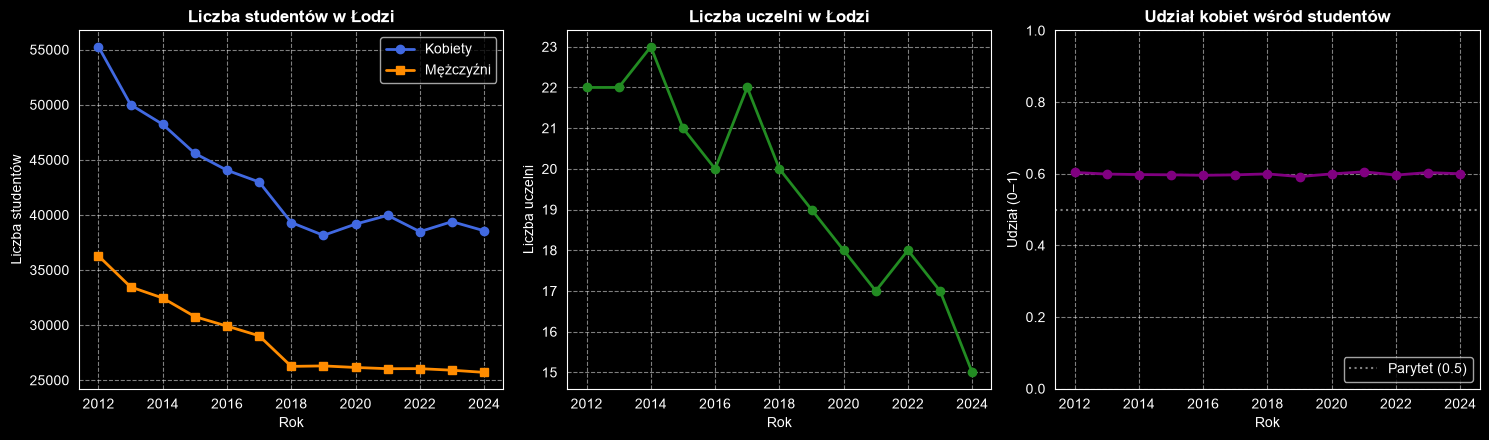

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# TODO: wykres 1 — kobiety i mężczyźni
axes[0].plot(szeroka.index, szeroka["kobiety"], marker="o", linewidth=2, color="royalblue", label="Kobiety")
axes[0].plot(szeroka.index, szeroka["mężczyźni"], marker="s", linewidth=2, color="darkorange", label="Mężczyźni")
axes[0].set_title("Liczba studentów w Łodzi", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba studentów")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(loc="upper right")

# TODO: wykres 2 — uczelnie
axes[1].plot(szeroka.index, szeroka["uczelnie"], marker="o", linewidth=2, color="forestgreen")
axes[1].set_title("Liczba uczelni w Łodzi", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba uczelni")
axes[1].grid(True, linestyle="--", alpha=0.5)

# TODO: wykres 3 — udział kobiet
axes[2].plot(szeroka.index, szeroka["udzial_kobiet"], marker="o", linewidth=2, color="purple")
axes[2].axhline(0.5, color="gray", linestyle=":", label="Parytet (0.5)")
axes[2].set_ylim(0, 1)
axes[2].set_title("Udział kobiet wśród studentów", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Rok")
axes[2].set_ylabel("Udział (0–1)")
axes[2].grid(True, linestyle="--", alpha=0.5)
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()


✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* W latach 2012–2024 liczba studentów w Łodzi uległa wyraźnemu spadkowi o ok. 29,8%, a liczba absolwentów zmniejszyła się aż o 41,3%, co zbiegło się w czasie z redukcją liczby funkcjonujących uczelni z 22 do 15. Najostrzejszy spadek przypadał na lata 2012–2018, po czym od 2019 roku wielkość populacji studentów ustabilizowała się na poziomie ok. 64–66 tys. Pomimo zauważalnego zmniejszenia skali środowiska akademickiego, struktura płciowa pozostała stabilna – odsetek kobiet niezmiennie oscylował wokół 60%.


## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** Przeciętne miesięczne wynagrodzenia brutto ogółem · **link:** https://otwarte.miasto.lodz.pl/dataset/przecietne-miesieczne-wynagrodzenia-brutto-ogolem · **data pobrania:** 27.10.2026


In [13]:
# TODO: wczytanie i przegląd Twojego zbioru
# Dataset: Przeciętne miesięczne wynagrodzenia brutto ogółem
# Link: https://otwarte.miasto.lodz.pl/dataset/przecietne-miesieczne-wynagrodzenia-brutto-ogolem
# Data: 27.10.2026

salary_file = "przecitne-miesiczne-wynagrodzenia-brutto-ogolem.csv"
upewnij_sie_ze_jest(salary_file)

# Load dataset specifying semicolon separator and decimal comma
df_salaries = pd.read_csv(salary_file, decimal=",", sep=";", encoding="utf-8")
print(f"Data shape: {df_salaries.shape}")
print("\nFirst rows:")
print(df_salaries.head())

# Extract salary series indexed by year
wyn = df_salaries.set_index("rok")["wartość"].rename("wynagrodzenie")


Plik przecitne-miesiczne-wynagrodzenia-brutto-ogolem.csv jest na miejscu.
Data shape: (23, 4)

First rows:
      id   rok  wartość                                            zmienne
0  64428  2002  2102.42  Przeciętne miesięczne wynagrodzenia brutto ogólem
1  64428  2003  2164.79  Przeciętne miesięczne wynagrodzenia brutto ogólem
2  64428  2004  2293.67  Przeciętne miesięczne wynagrodzenia brutto ogólem
3  64428  2005  2401.67  Przeciętne miesięczne wynagrodzenia brutto ogólem
4  64428  2006  2500.84  Przeciętne miesięczne wynagrodzenia brutto ogólem


Summary statistics:
count     23.00
mean    4138.14
std     1764.46
min     2102.42
25%     2850.11
50%     3710.91
75%     4977.16
max     8621.77
Name: wynagrodzenie, dtype: float64

Missing values per column:
id         0
rok        0
wartość    0
zmienne    0
dtype: int64
Duplicate years: False
Continuous years (no gaps): True

Total change 2002 -> 2024: 310.1%
Highest annual growth: 14.2% (2024)
Lowest annual growth:  2.7% (2010)


/var/folders/cp/30f0jyxn5nbf0xx50p5vsnh00000gn/T/ipykernel_27064/1231373988.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[2].boxplot(wyn, vert=True, patch_artist=True,


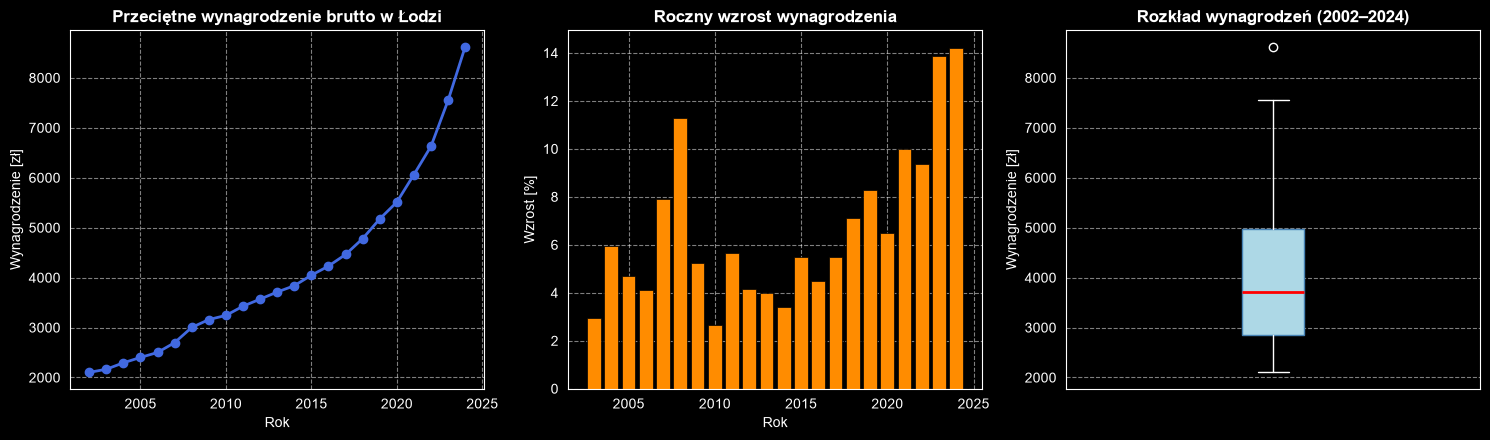

In [14]:
# TODO: przekształcenia, statystyki i wykresy

# 1. Summary statistics and data integrity checks
print("Summary statistics:")
print(wyn.describe())

print("\nMissing values per column:")
print(df_salaries.isna().sum())
print(f"Duplicate years: {df_salaries['rok'].duplicated().any()}")
print(f"Continuous years (no gaps): {(wyn.index.to_series().diff() == 1)[1:].all()}")

# 2. Percentage growth metrics
total_change_pct = ((wyn.loc[2024] - wyn.loc[2002]) / wyn.loc[2002]) * 100
annual_growth = wyn.pct_change() * 100
wzrost = annual_growth  # Alias

print(f"\nTotal change 2002 -> 2024: {total_change_pct:.1f}%")
print(f"Highest annual growth: {annual_growth.max():.1f}% ({annual_growth.idxmax()})")
print(f"Lowest annual growth:  {annual_growth.min():.1f}% ({annual_growth.idxmin()})")

# 3. Visualizations
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Plot 1: Nominal salary trend over years
axes[0].plot(wyn.index, wyn, marker="o", linewidth=2, color="royalblue")
axes[0].set_title("Przeciętne wynagrodzenie brutto w Łodzi", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Wynagrodzenie [zł]")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Year-over-year percentage growth
axes[1].bar(annual_growth.index, annual_growth, color="darkorange", edgecolor="black", linewidth=0.5)
axes[1].set_title("Roczny wzrost wynagrodzenia", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Wzrost [%]")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Plot 3: Distribution boxplot
axes[2].boxplot(wyn, vert=True, patch_artist=True,
                boxprops=dict(facecolor="lightblue", color="steelblue"),
                medianprops=dict(color="red", linewidth=2))
axes[2].set_title("Rozkład wynagrodzeń (2002–2024)", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Wynagrodzenie [zł]")
axes[2].set_xticks([])
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


✍️ **Wnioski:** Przeciętne wynagrodzenie brutto w Łodzi w latach 2002–2024 wzrosło z poziomu 2 102,42 zł do 8 621,77 zł, co stanowi wzrost nominalny o ok. 310,1% (średnio ok. 6,6% w skali roku). W całym 22-letnim okresie nie odnotowano spadku nominalnych wynagrodzeń r/r; najmniejszą dynamikę obserwowano w 2010 roku (2,7%, po kryzysie gospodarczym), natomiast rekordowe przyspieszenie nastąpiło w latach 2021–2024 (wzrosty roczne rzędu 10–14%), stymulowane głównie presją inflacyjną. Należy jednak zaznaczyć, że zestawienie operuje kwotami nominalnymi i bez uwzględnienia wskaźnika inflacji (CPI) nie odzwierciedla bezpośrednio realnej siły nabywczej pensji.


---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [15]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()

,patient_id,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,A456281,Male,25.00,0,0,False,student,Urban,77.47,35.66,formerly smoked,0
1,A730553,Male,16.00,0,0,True,student,Urban,83.78,34.76,never smoked,0
2,A800980,Male,19.00,0,0,True,Private,Urban,91.65,25.38,never smoked,0
3,A433166,Male,35.00,0,0,True,Self-employed,Urban,97.09,21.26,never smoked,0
4,A114521,Male,15.00,0,0,True,student,Urban,89.17,22.27,formerly smoked,0


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

Descriptive statistics for numeric columns:
          age     bmi  avg_glucose_level
count 3000.00 3000.00            3000.00
mean    45.25   26.29             134.00
std     20.83   15.88             181.27
min      0.67   -5.20             -21.40
25%     28.00   21.28              85.59
50%     49.00   24.70             101.40
75%     63.00   28.88             127.43
max     80.00  105.60            1254.60


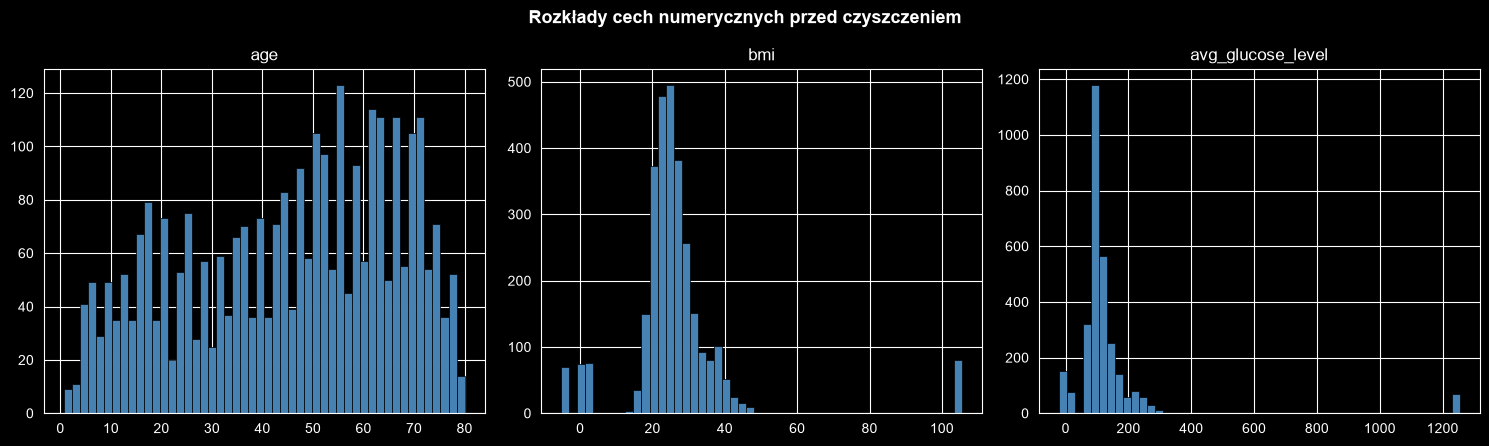

In [16]:
numeric_cols = ["age", "bmi", "avg_glucose_level"]
LICZBOWE = numeric_cols  # Compatibility alias

# TODO: statystyki opisowe
print("Descriptive statistics for numeric columns:")
print(pacjenci[numeric_cols].describe())

# TODO: histogramy (np. pacjenci[LICZBOWE].hist(...))
pacjenci[numeric_cols].hist(bins=50, figsize=(15, 4.5), layout=(1, 3), color="steelblue", edgecolor="black", linewidth=0.5)
plt.suptitle("Rozkłady cech numerycznych przed czyszczeniem", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:*

| Zmienna | Minimalna fizjologiczna | Maksymalna fizjologiczna | Wartości w danych (min – max) | Ocena poprawności |
|---|---|---|---|---|
| `age` | 0 lat | ok. 120 lat | 0.67 – 80.00 | W pełnym zakresie poprawne fizjologicznie. |
| `bmi` | ok. 10 kg/m² (skrajne wyniszczenie) | ok. 60 kg/m² (skrajna otyłość kliniczna) | -5.20 – 105.60 | Wartości ujemne oraz powyżej 60 są fizycznie niemożliwe. |
| `avg_glucose_level` | ok. 20–40 mg/dl (ciężka hipoglikemia) | ok. 600–800 mg/dl (ostry przełom cukrzycowy) | -21.40 – 1254.60 | Wartości ujemne oraz powyżej 800 to błędy aparatury bądź zapisu. |

Wniosek: Zmienna wieku nie wykazuje anomalii fizjologicznych. Natomiast w przypadku BMI oraz stężenia glukozy minima (wartości ujemne) i maksima wykraczają daleko poza granice biologicznego przeżycia człowieka — są to bezsprzeczne błędy w danych, a nie rzadkie stany chorobowe.


## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [17]:
# TODO: maski
invalid_bmi = ~pacjenci["bmi"].between(10, 60) & pacjenci["bmi"].notna()
invalid_glucose = ~pacjenci["avg_glucose_level"].between(20, 800) & pacjenci["avg_glucose_level"].notna()
invalid_age = ~pacjenci["age"].between(0, 120) & pacjenci["age"].notna()

# Compatibility aliases
zle_bmi = invalid_bmi
zla_glukoza = invalid_glucose
zly_wiek = invalid_age

# TODO: liczebności
print(f"Niemożliwe BMI:     {invalid_bmi.sum()}")
print(f"Niemożliwa glukoza: {invalid_glucose.sum()}")
print(f"Niemożliwy wiek:    {invalid_age.sum()}")

any_invalid = invalid_bmi | invalid_glucose | invalid_age
print(f"Pacjenci z co najmniej jedną niemożliwą wartością: {any_invalid.sum()}")

# TODO: zamiana na NaN
pacjenci.loc[invalid_bmi, "bmi"] = np.nan
pacjenci.loc[invalid_glucose, "avg_glucose_level"] = np.nan
pacjenci.loc[invalid_age, "age"] = np.nan


Niemożliwe BMI:     300
Niemożliwa glukoza: 300
Niemożliwy wiek:    0
Pacjenci z co najmniej jedną niemożliwą wartością: 560


Summary statistics after cleaning impossible values:
          age     bmi  avg_glucose_level
count 3000.00 2700.00            2700.00
mean    45.25   26.12             116.84
std     20.83    5.84              44.45
min      0.67   13.57              44.76
25%     28.00   21.94              89.47
50%     49.00   24.98             103.09
75%     63.00   28.85             127.84
max     80.00   47.62             332.91

Missing values (NaN) count:
{'age': 0, 'bmi': 300, 'avg_glucose_level': 300}


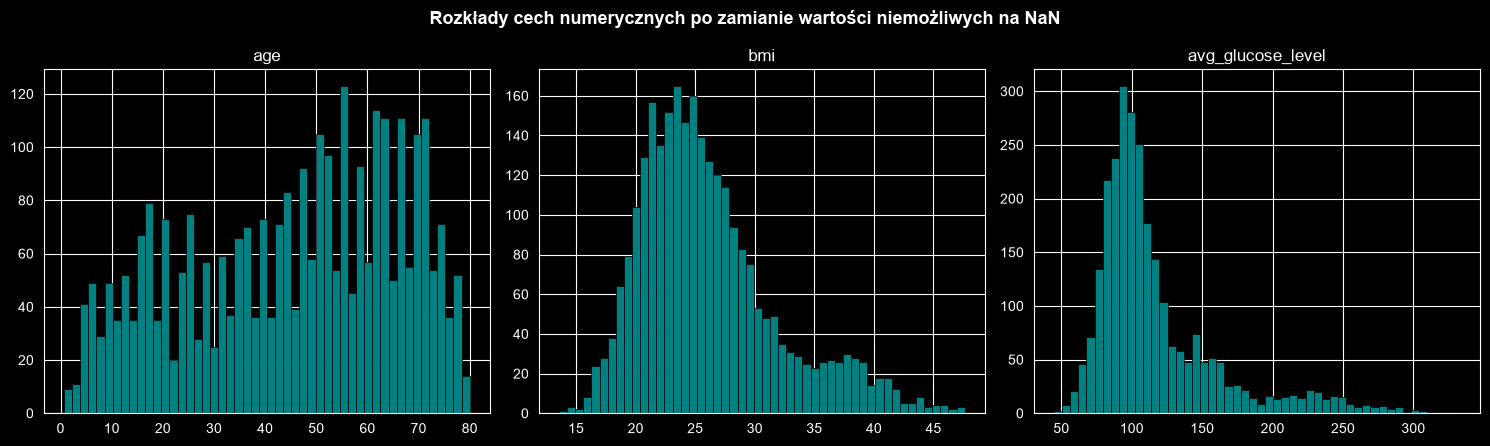

In [18]:
# TODO: ponownie statystyki opisowe i histogramy — co się zmieniło?
print("Summary statistics after cleaning impossible values:")
print(pacjenci[numeric_cols].describe())

print("\nMissing values (NaN) count:")
print(pacjenci[numeric_cols].isna().sum().to_dict())

pacjenci[numeric_cols].hist(bins=50, figsize=(15, 4.5), layout=(1, 3), color="teal", edgecolor="black", linewidth=0.5)
plt.suptitle("Rozkłady cech numerycznych po zamianie wartości niemożliwych na NaN", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

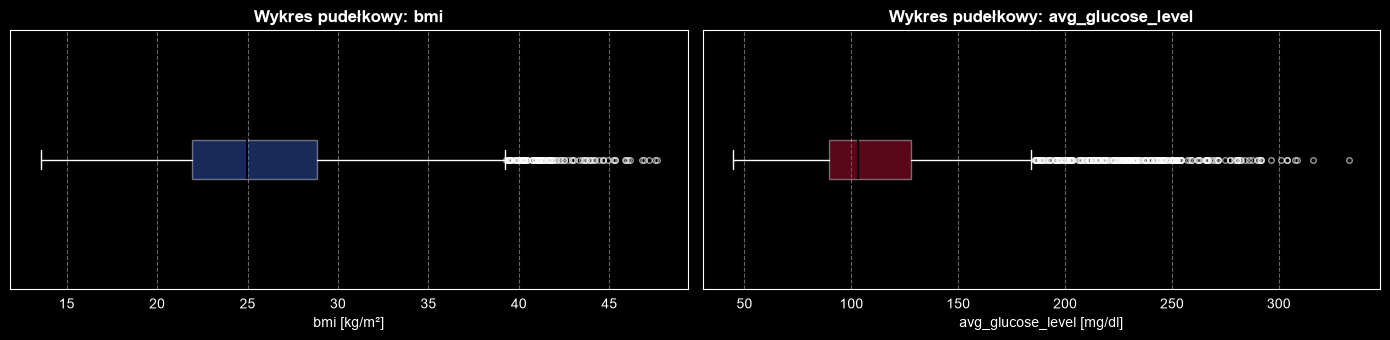

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))

# TODO: wykresy pudełkowe bmi i glukozy
box_configs = [
    ("bmi", "kg/m²", "royalblue"),
    ("avg_glucose_level", "mg/dl", "crimson")
]

for ax, (col_name, unit, color) in zip(axes, box_configs):
    ax.boxplot(
        pacjenci[col_name].dropna(),
        orientation="horizontal",
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.4),
        medianprops=dict(color="black", linewidth=1.5),
        flierprops=dict(marker="o", color=color, alpha=0.6, markersize=4)
    )
    ax.set_title(f"Wykres pudełkowy: {col_name}", fontsize=12, fontweight="bold")
    ax.set_xlabel(f"{col_name} [{unit}]")
    ax.set_yticks([])
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


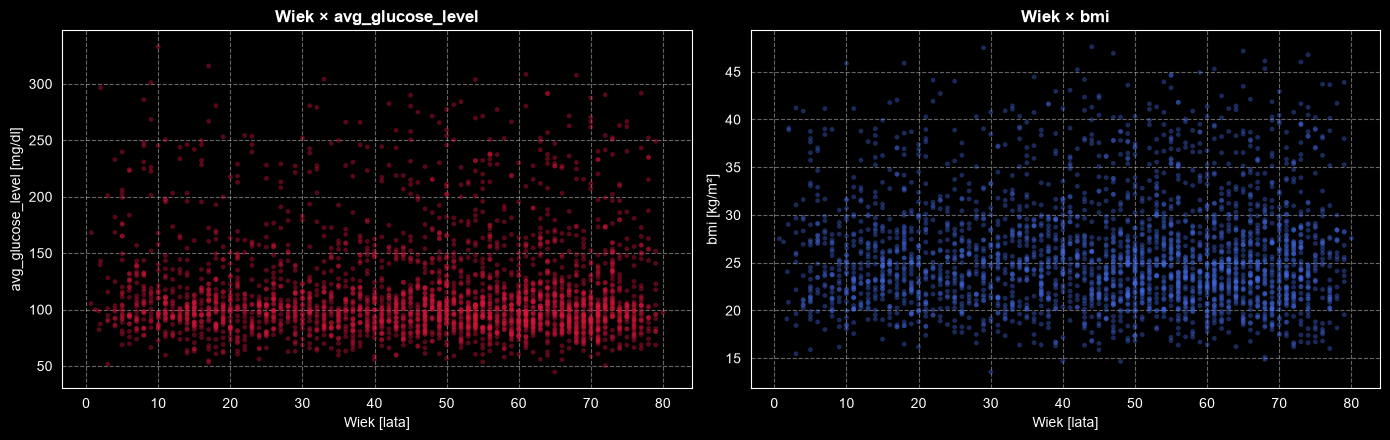

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# TODO: wykresy punktowe age × glukoza i age × bmi
scatter_configs = [
    ("avg_glucose_level", "mg/dl", "crimson"),
    ("bmi", "kg/m²", "royalblue")
]

for ax, (col_name, unit, color) in zip(axes, scatter_configs):
    ax.scatter(pacjenci["age"], pacjenci[col_name], s=12, alpha=0.4, color=color, edgecolors="none")
    ax.set_title(f"Wiek × {col_name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Wiek [lata]")
    ax.set_ylabel(f"{col_name} [{unit}]")
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:*
1. **Punkty poza wąsami:** Znacznie więcej obserwacji odstających wykazuje poziom glukozy (`avg_glucose_level`) niż `bmi` (235 punktów wobec 100). W obu przypadkach punkty leżą **wyłącznie po prawej stronie** pudełka (wartości wysokie). Wynika to z silnej asymetrii prawostronnej obu rozkładów i obecności wydłużonego prawego ogona przy braku skrajnie niskich wartości po lewej stronie.
2. **Wykres punktowy wiek × glukoza:** Wysoki poziom glukozy (>200 mg/dl) występuje przekrojowo w każdym wieku, od małych dzieci po osoby w podeszłym wieku. Przypadek 10-latka ze stężeniem glukozy >300 mg/dl mieści się w granicach biologicznej możliwości (np. ostry debiut cukrzycy typu 1 z kwasicą ketonową), dlatego jest to raczej **rzadki przypadek kliniczny** podlegający weryfikacji i oznaczeniu flagą, niż automatycznie odrzucany błąd pomiaru.


## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [21]:
def maska_iqr(s: pd.Series, k: float = 1.5) -> pd.Series:
    """Identify outliers using the Interquartile Range (IQR) rule."""
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def maska_z(s: pd.Series, prog: float = 3.0) -> pd.Series:
    """Identify outliers using standard z-score threshold."""
    z_scores = (s - s.mean()) / s.std()
    return z_scores.abs() > prog

def maska_mad(s: pd.Series, prog: float = 3.5) -> pd.Series:
    """Identify outliers using Median Absolute Deviation (MAD)."""
    median_val = s.median()
    mad_val = (s - median_val).abs().median()
    modified_z = (0.6745 * (s - median_val)) / mad_val
    return modified_z.abs() > prog


Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [22]:
# TODO: tabela porównawcza `porownanie`
porownanie = pd.DataFrame({
    "IQR 1,5": [maska_iqr(pacjenci[col]).sum() for col in numeric_cols],
    "IQR 3": [maska_iqr(pacjenci[col], k=3.0).sum() for col in numeric_cols],
    "z-score": [maska_z(pacjenci[col], prog=3.0).sum() for col in numeric_cols],
    "MAD": [maska_mad(pacjenci[col], prog=3.5).sum() for col in numeric_cols],
    "skośność": [pacjenci[col].skew() for col in numeric_cols],
}, index=numeric_cols)

porownanie


,"IQR 1,5",IQR 3,z-score,MAD,skośność
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:*
Dla glukozy wyniki poszczególnych metod drastycznie się różnią ze względu na wysoką asymetrię prawostronną (`skośność = 1.80`) oraz obecność podgrupy pacjentów z hiperglikemią (garb w okolicy 200–250 mg/dl):
- **IQR 1.5** oraz **MAD** opierają się na miarach odpornych (mediana, kwartyle), wyznaczonych na gęstym, zdrowym centrum rozkładu (~100 mg/dl). W konsekwencji klasyfikują one niemal cały prawy ogon jako wartości odstające (odpowiednio 235 i 223 obserwacje).
- **z-score** zakłada rozkład zbliżony do normalnego. Ponieważ prawy ogon silnie zawyża średnią oraz odchylenie standardowe ($s \approx 44$), próg $\bar{x} + 3s$ przesuwa się w prawo (efekt maskowania). Z tego powodu z-score identyfikuje zaledwie 62 punkty.
- **Wiek (`age`)** ma rozkład zbliżony do jednostajnego na ograniczonym przedziale 0–80 lat, o minimalnej ujemnej asymetrii (`skośność = -0.33`) i całkowitym braku długich ogonów. Żadna obserwacja nie oddala się istotnie od centrum rozkładu, dlatego żadna metoda nie wskazuje anomalii.


### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

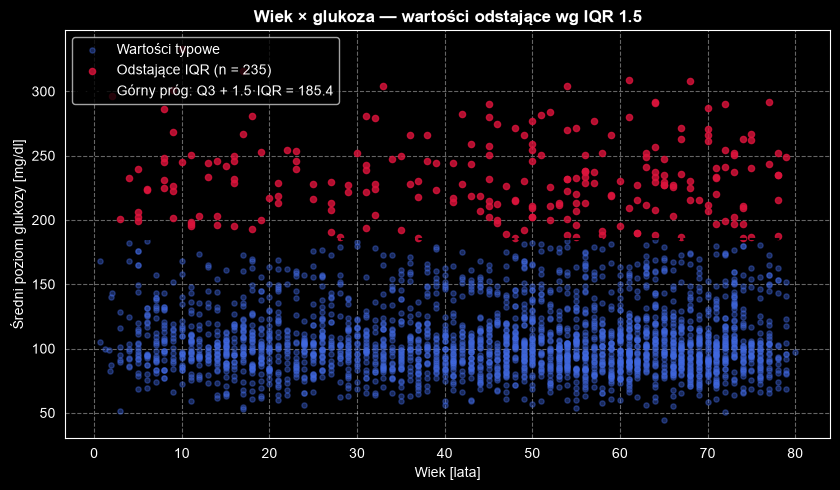

Points above upper bound: 235 | Points below lower bound: 0


In [23]:
# TODO: wykres punktowy z zaznaczonymi wartościami odstającymi
glucose_col = pacjenci["avg_glucose_level"]
is_outlier_iqr = maska_iqr(glucose_col, k=1.5)

q1_glucose = glucose_col.quantile(0.25)
q3_glucose = glucose_col.quantile(0.75)
upper_bound = q3_glucose + 1.5 * (q3_glucose - q1_glucose)
lower_bound = q1_glucose - 1.5 * (q3_glucose - q1_glucose)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(pacjenci.loc[~is_outlier_iqr, "age"], glucose_col[~is_outlier_iqr],
           s=14, alpha=0.4, color="royalblue", label="Wartości typowe")
ax.scatter(pacjenci.loc[is_outlier_iqr, "age"], glucose_col[is_outlier_iqr],
           s=20, alpha=0.8, color="crimson", label=f"Odstające IQR (n = {is_outlier_iqr.sum()})")

ax.axhline(upper_bound, color="black", linestyle="--", linewidth=1.5,
           label=f"Górny próg: Q3 + 1.5·IQR = {upper_bound:.1f}")

ax.set_title("Wiek × glukoza — wartości odstające wg IQR 1.5", fontsize=12, fontweight="bold")
ax.set_xlabel("Wiek [lata]")
ax.set_ylabel("Średni poziom glukozy [mg/dl]")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

# Compatibility variables for following cells
glu = glucose_col
odst = is_outlier_iqr
gorna = upper_bound

print(f"Points above upper bound: {(glucose_col > upper_bound).sum()} | Points below lower bound: {(glucose_col < lower_bound).sum()}")


### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

Odsetek udarów w grupach:
                   odsetek  liczba
avg_glucose_level                 
glukoza odstająca    21.70     235
pozostali            21.10    2465


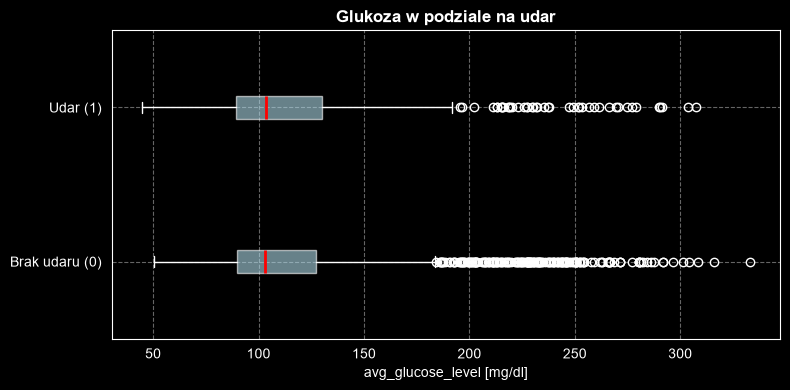

In [24]:
# TODO: odsetek udarów w obu grupach (tylko pacjenci ze znaną glukozą)
valid_glucose = pacjenci["avg_glucose_level"].notna()
glucose_group = is_outlier_iqr[valid_glucose].map({True: "glukoza odstająca", False: "pozostali"})

stroke_rate_summary = pacjenci.loc[valid_glucose].groupby(glucose_group)["stroke"].agg(
    odsetek=lambda s: s.mean() * 100,
    liczba="size"
)
print("Odsetek udarów w grupach:")
print(stroke_rate_summary)

# TODO: boxplot glukozy w podziale na stroke
fig, ax = plt.subplots(figsize=(8, 4))
glucose_by_stroke_group = [
    pacjenci.loc[pacjenci["stroke"] == s, "avg_glucose_level"].dropna()
    for s in (0, 1)
]

ax.boxplot(
    glucose_by_stroke_group,
    orientation="horizontal",
    tick_labels=["Brak udaru (0)", "Udar (1)"],
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", alpha=0.6),
    medianprops=dict(color="red", linewidth=2)
)
ax.set_title("Glukoza w podziale na udar", fontsize=12, fontweight="bold")
ax.set_xlabel("avg_glucose_level [mg/dl]")
ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:*
Nie należy ich usuwać. Wysokie wartości glukozy są biologicznie uzasadnione (np. cukrzyca) i stanowią jeden z kluczowych klinicznych czynników ryzyka udaru mózgu. Arbitralne usunięcie takich pacjentów pozbawiłoby model danych o najciężej chorych przypadkach, zaburzając jego zdolność do trafnej diagnozy w warunkach rzeczywistych. Chociaż w tym sztucznie wygenerowanym zbiorze odsetek udarów w obu podgrupach jest niemal identyczny (~21,7% vs 21,1%), prawidłowym postępowaniem jest zachowanie tych rekordów, ewentualnie opatrzenie ich flagą hiperglikemii lub zastosowanie transformacji logarytmicznej w celu ograniczenia skośności.


## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [25]:
# TODO: tabela krzyżowa
print("Cross-tabulation: work_type vs smoking_status:")
print(pd.crosstab(pacjenci["work_type"], pacjenci["smoking_status"]))

print("\nAge ranges by work_type:")
print(pacjenci.groupby("work_type")["age"].agg(["min", "max"]))

# TODO: maski
invalid_child_smoker = (pacjenci["work_type"] == "children") & pacjenci["smoking_status"].isin(["smokes", "formerly smoked"])
invalid_toddler_student = (pacjenci["age"] <= 3) & (pacjenci["work_type"] == "student")

# Keep aliases for later summary
dziecko_pali = invalid_child_smoker
maluch_student = invalid_toddler_student

print(f"\nDziecko pali: {invalid_child_smoker.sum()} | Maluch-student: {invalid_toddler_student.sum()}")

illogical_records = pacjenci.loc[invalid_child_smoker | invalid_toddler_student, ["patient_id", "age", "work_type", "smoking_status"]]
illogical_records


Cross-tabulation: work_type vs smoking_status:
smoking_status  Unknown  formerly smoked  never smoked  smokes
work_type                                                     
Govt_job             16               63            94      67
Never_worked          1               30            36      35
Private              76              440           585     445
Self-employed        18              137           166     131
children             17                0           274      15
student              22               67           190      75

Age ranges by work_type:
                min   max
work_type                
Govt_job      30.00 77.00
Never_worked  31.00 79.00
Private       15.00 80.00
Self-employed  9.00 79.00
children       0.67 14.00
student        1.80 29.00

Dziecko pali: 15 | Maluch-student: 1


,patient_id,age,work_type,smoking_status
52,A582477,1.80,student,formerly smoked
111,A678646,9.00,children,smokes
290,A844121,13.00,children,smokes
336,A135365,12.00,children,smokes
352,A810636,14.00,children,smokes
361,A843508,2.00,children,smokes
578,A161666,3.00,children,smokes
600,A623587,10.00,children,smokes
613,A892803,13.00,children,smokes
741,A560170,13.00,children,smokes


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:*
Nie, metody IQR oraz z-score nie mogłyby wykryć tych przypadków z dwóch przyczyn:
1. **Ograniczenie do cech numerycznych:** Zarówno IQR, jak i z-score służą do analizy zmiennych ciągłych (ilościowych) i nie mają zastosowania do danych nominalnych i kategorycznych (`work_type`, `smoking_status`).
2. **Jednowymiarowość:** Każda wartość rozpatrywana w izolacji jest w 100% poprawna statystycznie i dopuszczalna (wiek 2 lata to naturalny wiek, status `student` to poprawna kategoria zatrudnienia, a `smokes` to poprawny status palenia). Niespójność ujawnia się dopiero w **relacji dwuwymiarowej (sprzeczność logiczna między kolumnami)**, czego żadna jednowymiarowa metoda analizy rozkładu nie jest w stanie zarejestrować.


## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [26]:
from scipy.stats import chi2

# TODO: X, Z, d2, prog
# 1. Kolumny LICZBOWE bez braków
X = pacjenci[numeric_cols].dropna()

# 2. Standaryzacja i kwadrat odległości euklidesowej od środka
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)

# 3. Próg chi2 dla 3 cech na poziomie kwantyla 0.99
degrees_of_freedom = len(numeric_cols)
chi2_threshold = chi2.ppf(0.99, df=degrees_of_freedom)
prog = chi2_threshold
odstajacy = d2 > chi2_threshold

print(f"Próg chi² (p=0.99, df={degrees_of_freedom}): {chi2_threshold:.4f}")
print(f"Liczba pacjentów odstających (d² > próg): {odstajacy.sum()} / {len(X)} ({odstajacy.mean():.2%})")

# 4. Która cecha ma największy udział w d² u tych pacjentów
squared_z = Z.loc[odstajacy] ** 2
glowna_cecha = squared_z.idxmax(axis=1)

print("\nNajwiększy wkład w d² u pacjentów odstających:")
print(glowna_cecha.value_counts())


Próg chi² (p=0.99, df=3): 11.3449
Liczba pacjentów odstających (d² > próg): 73 / 2440 (2.99%)

Największy wkład w d² u pacjentów odstających:
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Liczba odstających po zlogarytmowaniu glukozy: 31 (spadek z 73)

Największy wkład w d²_log po transformacji:
bmi                  22
avg_glucose_level     9
Name: count, dtype: int64


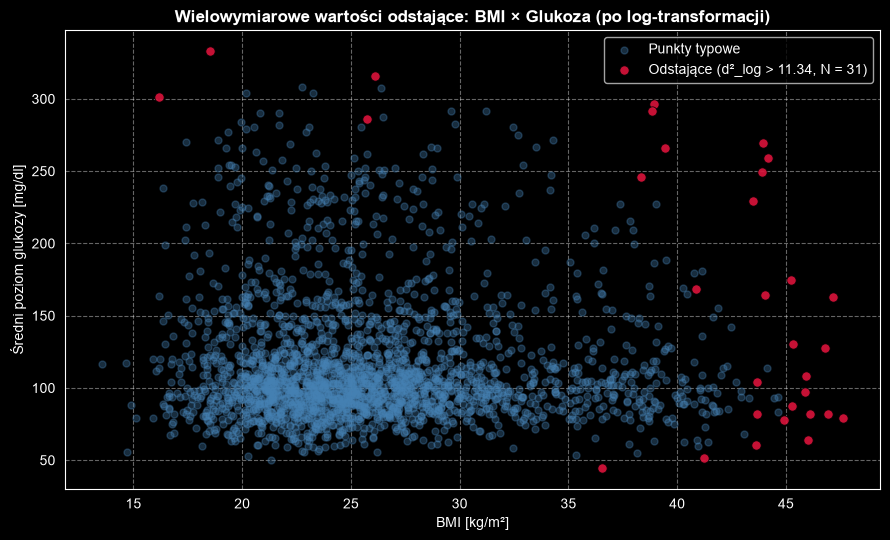

In [27]:
# TODO: X_log, Z_log, d2_log i liczba odstających
X_log = X.copy()
X_log["avg_glucose_level"] = np.log(X_log["avg_glucose_level"])

Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
odstajacy_log = d2_log > prog

print(f"Liczba odstających po zlogarytmowaniu glukozy: {odstajacy_log.sum()} (spadek z {odstajacy.sum()})")
print("\nNajwiększy wkład w d²_log po transformacji:")
print((Z_log.loc[odstajacy_log] ** 2).idxmax(axis=1).value_counts())

# TODO: wykres punktowy
plt.figure(figsize=(9, 5.5))
plt.scatter(X.loc[~odstajacy_log, "bmi"], X.loc[~odstajacy_log, "avg_glucose_level"],
            c="steelblue", alpha=0.35, s=25, label="Punkty typowe")
plt.scatter(X.loc[odstajacy_log, "bmi"], X.loc[odstajacy_log, "avg_glucose_level"],
            c="crimson", alpha=0.9, s=45, edgecolor="black", linewidth=0.6,
            label=f"Odstające (d²_log > {prog:.2f}, N = {odstajacy_log.sum()})")

plt.xlabel("BMI [kg/m²]")
plt.ylabel("Średni poziom glukozy [mg/dl]")
plt.title("Wielowymiarowe wartości odstające: BMI × Glukoza (po log-transformacji)", fontsize=12, fontweight="bold")
plt.legend(frameon=True, loc="upper right")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:*
Nie, w tym wypadku odległość Mahalanobisa dałaby praktycznie identyczne rezultaty jak wystandaryzowana odległość euklidesowa.

Kwadrat odległości Mahalanobisa definiowany jest wzorem:
$$ d_M^2 = (x - \mu)^T \Sigma^{-1} (x - \mu) $$
gdzie $\Sigma$ stanowi macierz kowariancji. Ponieważ korelacje liniowe pomiędzy wiekiem, BMI i poziomem glukozy są znikome ($|r| < 0.025$), macierz kowariancji ma strukturę niemal idealnie diagonalną. W takiej sytuacji jej odwrotność $\Sigma^{-1}$ zawiera na przekątnej jedynie odwrotności wariancji cech ($1/s_j^2$), a elementy pozaprzekątne redukują się do zera. Wzór Mahalanobisa sprowadza się więc wprost do sumy kwadratów z-score'ów:
$$ d_M^2 \approx \sum_{j=1}^{p} \frac{(x_j - \bar{x}_j)^2}{s_j^2} = d^2 $$
Odległość Mahalanobisa wnosi przewagę dopiero wówczas, gdy pomiędzy zmiennymi występują wyraźne korelacje – wówczas uwzględnia ona ukośną geometrię chmury punktów.


### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [28]:
# TODO (dla chętnych)
from sklearn.ensemble import IsolationForest

iso_forest = IsolationForest(contamination=0.01, random_state=0)
forest_preds = iso_forest.fit_predict(X_log)  # -1 = anomalia, 1 = punkt typowy
iso_odstajace = pd.Series(forest_preds == -1, index=X_log.index)

wspolne = iso_odstajace & odstajacy_log

print(f"Isolation Forest wykrył odstających:  {iso_odstajace.sum()}")
print(f"Odległość d²_log wykryła odstających:  {odstajacy_log.sum()}")
print(f"Wspólne wskazania obu metod:           {wspolne.sum()} ({wspolne.sum() / iso_odstajace.sum():.1%} pokrycia IF)")


Isolation Forest wykrył odstających:  25
Odległość d²_log wykryła odstających:  31
Wspólne wskazania obu metod:           19 (76.0% pokrycia IF)


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [29]:
# TODO: ramka flagi
flagi = pd.DataFrame(index=oryginal.index)

# Krok 1: Niemożliwe wartości fizjologiczne
flagi["niemozliwa_wartosc"] = invalid_bmi | invalid_glucose | invalid_age

# Krok 2: Wartości odstające glukozy wg IQR 1.5
flagi["glukoza_iqr"] = maska_iqr(pacjenci["avg_glucose_level"], k=1.5)

# Krok 3: Nielogiczne kombinacje kategorii
flagi["nielogiczna_kategoria"] = invalid_child_smoker | invalid_toddler_student

# Krok 4: Nietypowe kombinacje liczb (d2_log > próg chi2; pacjenci bez obliczonej odległości -> False)
flagi["odlegly_od_srodka"] = False
flagi.loc[odstajacy_log.index, "odlegly_od_srodka"] = odstajacy_log

print("Liczba pacjentów z poszczególnymi flagami anomalii:")
print(flagi.sum())
print("-" * 50)
total_anomalies = flagi.any(axis=1).sum()
pct_anomalies = flagi.any(axis=1).mean() * 100
print(f"Pacjenci z co najmniej jedną flagą: {total_anomalies} / {len(flagi)} ({pct_anomalies:.1f}%)")


Liczba pacjentów z poszczególnymi flagami anomalii:
niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dtype: int64
--------------------------------------------------
Pacjenci z co najmniej jedną flagą: 806 / 3000 (26.9%)


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Proponowana strategia | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | **zamiana na `NaN` (lub usunięcie / imputacja)** | Są to oczywiste błędy wprowadzania danych bądź awarie aparatury pomiarowej (np. ujemne wartości BMI i glukozy), które zakłócają statystyki i nie mają uzasadnienia biologicznego. |
| wysoka glukoza (IQR) | **zostawić + flaga lub transformacja logarytmiczna** | Wartości te są fizjologicznie wiarygodne i stanowią istotny medyczny predyktor udaru mózgu; ich arbitralne usunięcie zubożyłoby zdolność predykcyjną modelu. |
| nielogiczne kategorie | **poprawić (regułą dziedzinową) / zamiana na `NaN`** | Wynikają z ewidentnych pomyłek rejestracyjnych (np. 2-latek jako student lub palące niemowlę); pojedyncze wartości są poprawne, lecz ich łączny stan logiczny jest fikcyjny. |
| odlegli od środka | **flaga ostrzegawcza / indywidualna inspekcja** | Pacjenci o rzadkich kombinacjach cech; warto oznaczyć ich flagą informacyjną w procesie modelowania, unikając nieuzasadnionego usuwania potencjalnie poprawnych obserwacji wielowymiarowych. |
